# Análisis exploratorio: ¿cómo se comporta `happiness_score`?

## Objetivos

1. Describir la distribución del objetivo y sus diferencias entre países y regiones.
2. Explorar su evolución entre 2015 y 2019 controlando los cambios de cobertura.
3. Examinar asociaciones con los seis predictores propuestos para regresión.
4. Identificar limitaciones que deben considerarse al interpretar y modelar los datos.

La unidad de observación es **país–año**. Las medias son promedios simples de países,
sin ponderación poblacional. Un mismo país aparece varias veces: las filas no son
observaciones independientes. Este EDA describe asociaciones, no efectos causales.
No se incorpora población porque no está disponible en estos datasets.

Ejecuta las celdas en orden. Cada figura se muestra aquí y se exporta como PNG a
`dashboards/screenshots/eda/`. Las tablas se guardan en `data/reports/eda/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'data/processed/happiness_analysis.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Ejecuta primero transform-data.ipynb.')
df_analisis = pd.read_csv(PROJECT_ROOT / 'data/processed/happiness_analysis.csv')
df_analisis_numerico = pd.read_csv(PROJECT_ROOT / 'data/processed/happiness_modeling.csv')
FEATURES = ['gdp_per_capita', 'social_support', 'healthy_life_expectancy',
            'freedom', 'generosity', 'corruption']
TARGET = 'happiness_score'
LABELS = {'gdp_per_capita': 'PIB per cápita (indicador)', 'social_support': 'Apoyo social',
          'healthy_life_expectancy': 'Esperanza de vida saludable (indicador)',
          'freedom': 'Libertad', 'generosity': 'Generosidad', 'corruption': 'Corrupción (indicador)'}
PALETTE = ['#ff26f8', '#e833f9', '#d140fa', '#b94cfb', '#a259fc',
           '#8b66fc', '#7473fd', '#5c7ffe', '#458cff']
YEAR_COLORS = dict(zip(sorted(df_analisis.year.unique()), [PALETTE[i] for i in [0, 2, 4, 6, 8]]))
FIG_DIR = PROJECT_ROOT / 'dashboards/screenshots/eda'
TABLE_DIR = PROJECT_ROOT / 'data/reports/eda'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 12, 'font.size': 10})

def finish(fig, filename):
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=160, bbox_inches='tight')
    plt.show()

assert not df_analisis.duplicated(['country', 'year']).any()
assert not df_analisis.isna().any(axis=None)
assert not df_analisis_numerico.isna().any(axis=None)
pd.testing.assert_frame_equal(
    df_analisis[['country', 'year'] + FEATURES + [TARGET]].reset_index(drop=True),
    df_analisis_numerico[['country', 'year'] + FEATURES + [TARGET]].reset_index(drop=True))
summary = df_analisis.groupby('year')[TARGET].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
display(summary.round(3))
display(df_analisis[[TARGET] + FEATURES].describe().round(3))
summary.to_csv(TABLE_DIR / 'summary_by_year.csv')
print('Filas:', len(df_analisis), '| Países distintos (nombres originales):', df_analisis.country.nunique())

      count   mean  median    std    min    max
year                                           
2015    158  5.376   5.232  1.145  2.839  7.587
2016    157  5.382   5.314  1.142  2.905  7.526
2017    155  5.354   5.279  1.131  2.693  7.537
2018    156  5.376   5.378  1.120  2.905  7.632
2019    156  5.407   5.380  1.113  2.853  7.769
       happiness_score  gdp_per_capita  ...  generosity  corruption
count          782.000         782.000  ...     782.000     782.000
mean             5.379           0.916  ...       0.219       0.125
std              1.127           0.407  ...       0.122       0.106
min              2.693           0.000  ...       0.000       0.000
25%              4.510           0.606  ...       0.130       0.054
50%              5.322           0.982  ...       0.202       0.091
75%              6.190           1.236  ...       0.279       0.156
max              7.769           2.096  ...       0.838       0.552

[8 rows x 7 columns]
Filas: 782 | Países distintos 

## 1. Distribución de la variable objetivo

El histograma describe la forma global y el boxplot permite comparar años usando
la misma escala. Los puntos fuera de los bigotes son señales exploratorias, no errores.

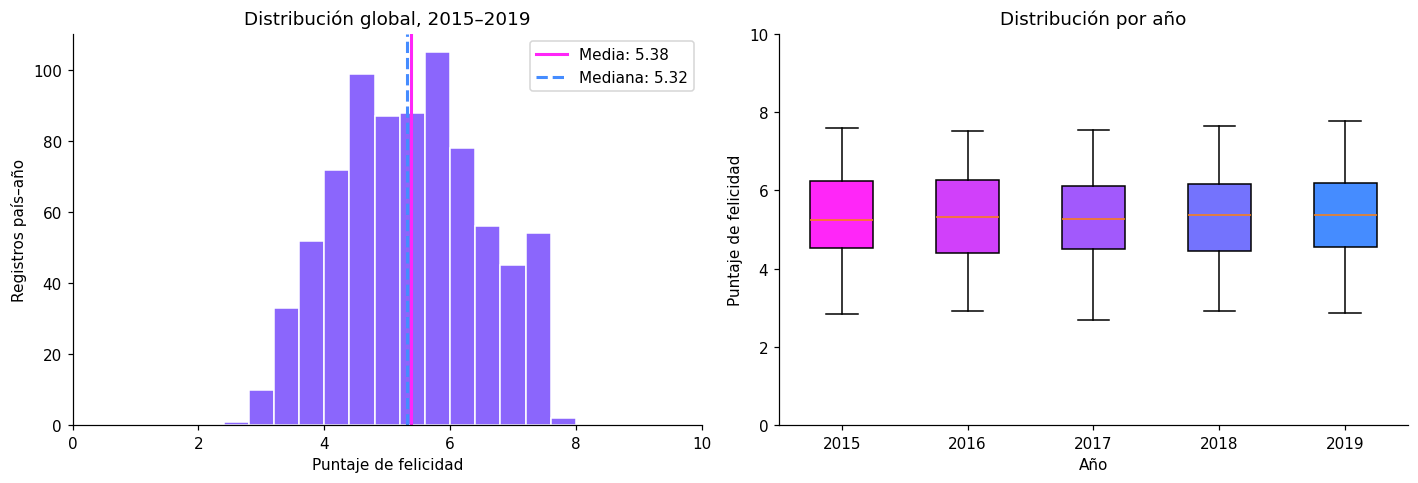

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
values = df_analisis[TARGET]
axes[0].hist(values, bins=np.linspace(0, 10, 26), color=PALETTE[5], edgecolor='white')
axes[0].axvline(values.mean(), color=PALETTE[0], label=f'Media: {values.mean():.2f}', linewidth=2)
axes[0].axvline(values.median(), color=PALETTE[-1], linestyle='--', label=f'Mediana: {values.median():.2f}', linewidth=2)
axes[0].set(title='Distribución global, 2015–2019', xlabel='Puntaje de felicidad', ylabel='Registros país–año', xlim=(0, 10))
axes[0].legend()
years = sorted(df_analisis.year.unique())
boxes = axes[1].boxplot([df_analisis.loc[df_analisis.year.eq(y), TARGET] for y in years], patch_artist=True)
for patch, y in zip(boxes['boxes'], years): patch.set_facecolor(YEAR_COLORS[y])
axes[1].set_xticks(range(1, len(years)+1), years)
axes[1].set(title='Distribución por año', xlabel='Año', ylabel='Puntaje de felicidad', ylim=(0, 10))
finish(fig, '01_target_distribution.png')

**Interpretación inicial.** Las medias anuales se sitúan entre 5,35 y 5,41; las medianas, entre 5,23 y 5,38. La variación entre países es mucho mayor que el cambio del promedio anual. Los cinco años muestran distribuciones de amplitud semejante; un promedio estable puede ocultar trayectorias nacionales distintas.


## 2. Diez países con mayor y menor felicidad

Seleccionamos países con registros en **los cinco años** y los ordenamos por su
puntaje medio 2015–2019. Cada caja resume cinco puntajes anuales del mismo país;
no es un intervalo de confianza ni una distribución de personas.

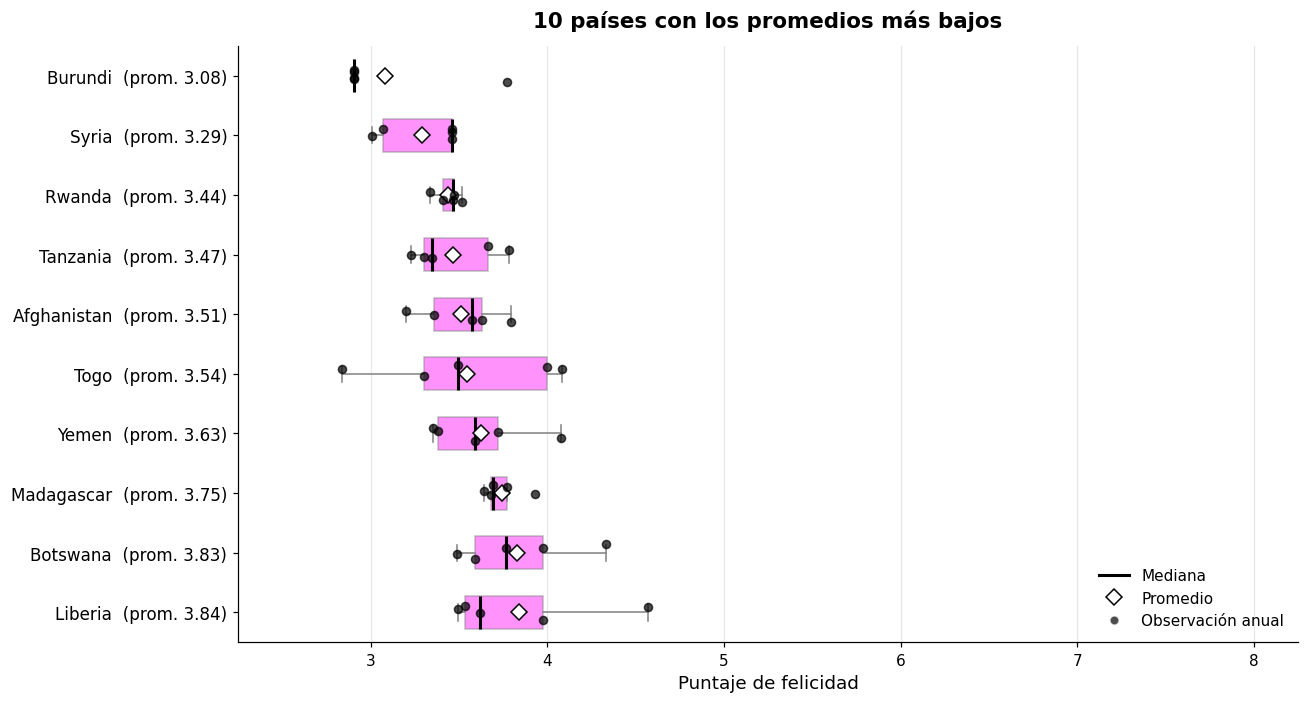

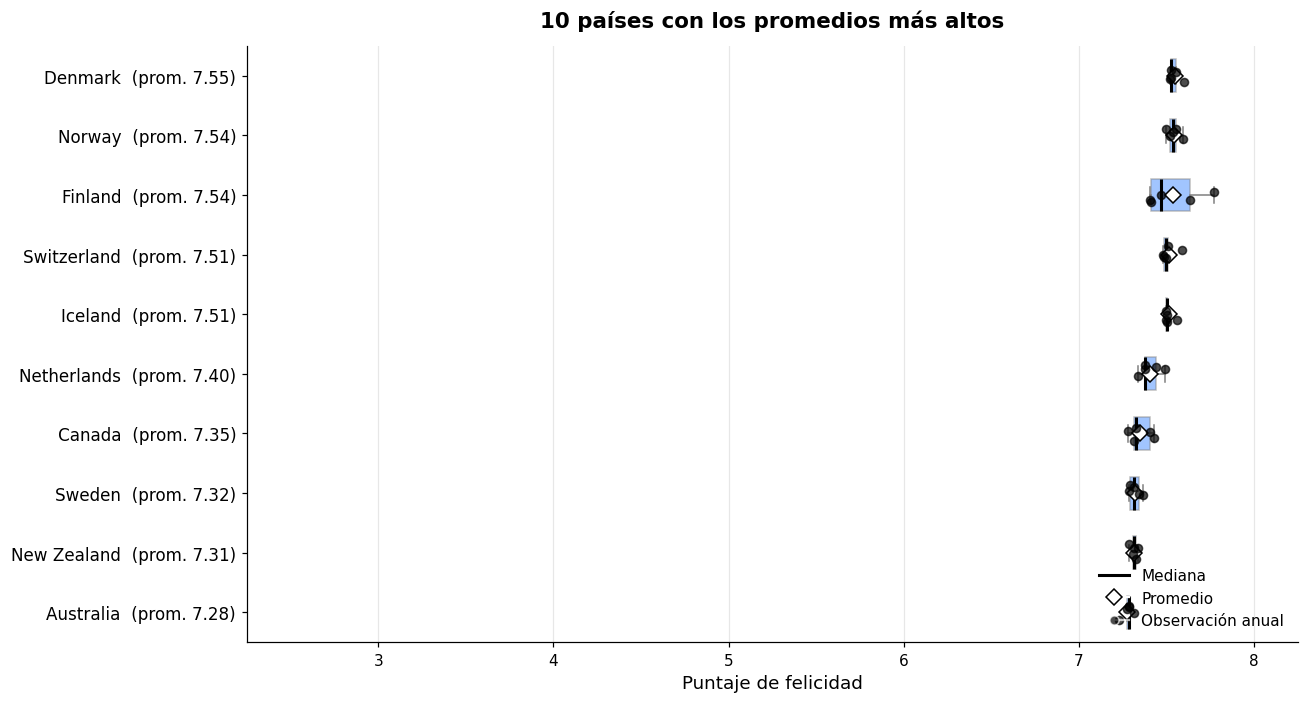

Panel comparable: 141 países con cinco observaciones cada uno.


In [3]:
coverage = df_analisis.groupby('country').year.nunique()
complete_countries = coverage.index[coverage.eq(len(years))]
panel = df_analisis[df_analisis.country.isin(complete_countries)].copy()
country_means = panel.groupby('country')[TARGET].mean().sort_values()
lowest = country_means.head(10).index.tolist()
highest = country_means.tail(10).index.tolist()

# Rango común para ambas figuras (se pueden comparar directamente)
sel = panel[panel.country.isin(lowest + highest)][TARGET]
xlim = (np.floor(sel.min() * 2) / 2 - 0.25, np.ceil(sel.max() * 2) / 2 + 0.25)

def plot_group(countries, title, color, filename, top_down_ascending):
    # En barras horizontales el primer elemento se dibuja abajo;
    # se ordena para que el país más relevante quede arriba.
    order = countries[::-1] if top_down_ascending else countries
    data = [panel.loc[panel.country.eq(c), TARGET].values for c in order]
    rng = np.random.default_rng(42)

    fig, ax = plt.subplots(figsize=(12, 6.5))
    boxes = ax.boxplot(
        data, vert=False, patch_artist=True, showmeans=True, widths=0.55,
        medianprops=dict(color='black', linewidth=2),
        meanprops=dict(marker='D', markerfacecolor='white',
                       markeredgecolor='black', markersize=7),
        whiskerprops=dict(color='gray'), capprops=dict(color='gray'),
        flierprops=dict(marker='', linestyle='none'),  # los puntos se dibujan abajo
    )
    for patch in boxes['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.5)
        patch.set_edgecolor('gray')

    # Observaciones individuales (5 por país) con pequeño desplazamiento vertical
    for i, vals in enumerate(data, start=1):
        ax.scatter(vals, i + rng.uniform(-0.15, 0.15, len(vals)),
                   s=28, color='black', alpha=0.7, zorder=3)

    labels = [f'{c}  (prom. {country_means[c]:.2f})' for c in order]
    ax.set_yticks(range(1, len(order) + 1))
    ax.set_yticklabels(labels, fontsize=11)
    ax.set_xlim(*xlim)
    ax.set_xlabel('Puntaje de felicidad', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)

    # Leyenda explicativa
    from matplotlib.lines import Line2D
    ax.legend(handles=[
        Line2D([0], [0], color='black', lw=2, label='Mediana'),
        Line2D([0], [0], marker='D', color='w', markerfacecolor='white',
               markeredgecolor='black', markersize=7, label='Promedio'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='black',
               alpha=0.7, markersize=6, label='Observación anual'),
    ], loc='lower right', frameon=False, fontsize=10)

    fig.tight_layout()
    finish(fig, filename)

plot_group(lowest, '10 países con los promedios más bajos',
           PALETTE[0], '02a_bottom_countries.png', top_down_ascending=True)
plot_group(highest, '10 países con los promedios más altos',
           PALETTE[-1], '02b_top_countries.png', top_down_ascending=False)

country_means.rename('mean_score').to_csv(TABLE_DIR / 'country_means_complete_panel.csv')
print(f'Panel comparable: {len(complete_countries)} países con cinco observaciones cada uno.')

**Interpretación inicial.** Entre los países con cobertura completa, Dinamarca presenta el mayor promedio (7,546) y Burundi el menor (3,079). La posición corresponde al promedio del período, no necesariamente al ranking de cada año. Las cajas permiten identificar países con puntajes más estables o más variables.

Los puntajes más bajos están entre 3 y 5. Los más altos entre 7 y 8 aproximadamente. 

## 4. Región y felicidad: comparación válida en 2015–2016

La región solo se publicó en esos dos años. Excluimos `Desconocido` de las comparaciones
geográficas y mostramos la cobertura por separado. No atribuimos regiones a 2017–2019.

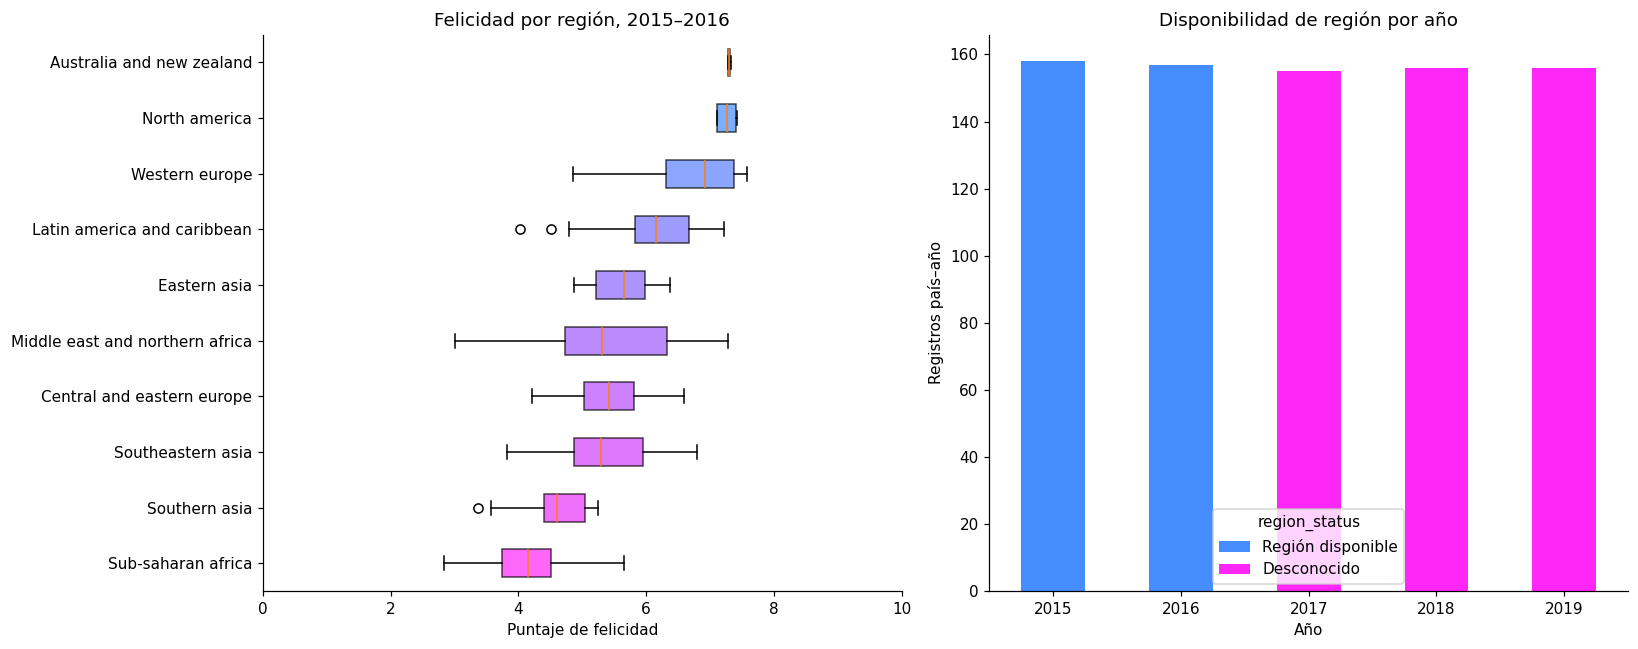

                                 count   mean  median    std
region                                                      
Sub-saharan africa                  78  4.170   4.148  0.582
Southern asia                       14  4.572   4.604  0.571
Southeastern asia                   18  5.328   5.296  0.912
Central and eastern europe          58  5.352   5.415  0.576
Middle east and northern africa     39  5.397   5.303  1.066
Eastern asia                        12  5.625   5.655  0.515
Latin america and caribbean         46  6.122   6.149  0.719
Western europe                      42  6.688   6.918  0.797
North america                        4  7.264   7.262  0.176
Australia and new zealand            4  7.304   7.300  0.024


In [4]:
known_regions = df_analisis[df_analisis.region.ne('Desconocido')].copy()
region_order = known_regions.groupby('region')[TARGET].mean().sort_values().index
region_summary = known_regions.groupby('region')[TARGET].agg(['count', 'mean', 'median', 'std']).loc[region_order]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
boxes = axes[0].boxplot([known_regions.loc[known_regions.region.eq(r), TARGET] for r in region_order],
                        vert=False, patch_artist=True)
for i, patch in enumerate(boxes['boxes']): patch.set_facecolor(PALETTE[i % len(PALETTE)]); patch.set_alpha(0.7)
axes[0].set_yticks(range(1, len(region_order)+1), region_order)
axes[0].set(title='Felicidad por región, 2015–2016', xlabel='Puntaje de felicidad', xlim=(0, 10))
region_coverage = (df_analisis.assign(region_status=np.where(df_analisis.region.eq('Desconocido'),
                    'Desconocido', 'Región disponible')).groupby(['year', 'region_status']).size()
                   .unstack(fill_value=0).reindex(columns=['Región disponible', 'Desconocido']))
region_coverage.plot.bar(stacked=True, ax=axes[1], color=[PALETTE[-1], PALETTE[0]], rot=0)
axes[1].set(title='Disponibilidad de región por año', xlabel='Año', ylabel='Registros país–año')
finish(fig, '04_regions_and_coverage.png')
display(region_summary.round(3))
region_summary.to_csv(TABLE_DIR / 'region_summary_2015_2016.csv')

**Interpretación inicial.** Las distribuciones regionales se superponen y tienen tamaños de muestra distintos. Las 467 observaciones sin región pertenecen a 2017–2019; compararlas como una región adicional mezclaría diferencias temporales y geográficas. Los conteos de la tabla son registros país–año, no personas ni países únicos.


## 5. Relaciones entre predictores y objetivo

Adaptamos el pairplot propuesto a seis dispersiones centradas en `happiness_score`.
El color identifica el año para detectar posibles diferencias de escala o metodología.
Se excluyen país, año y rango de los ejes de predictores.

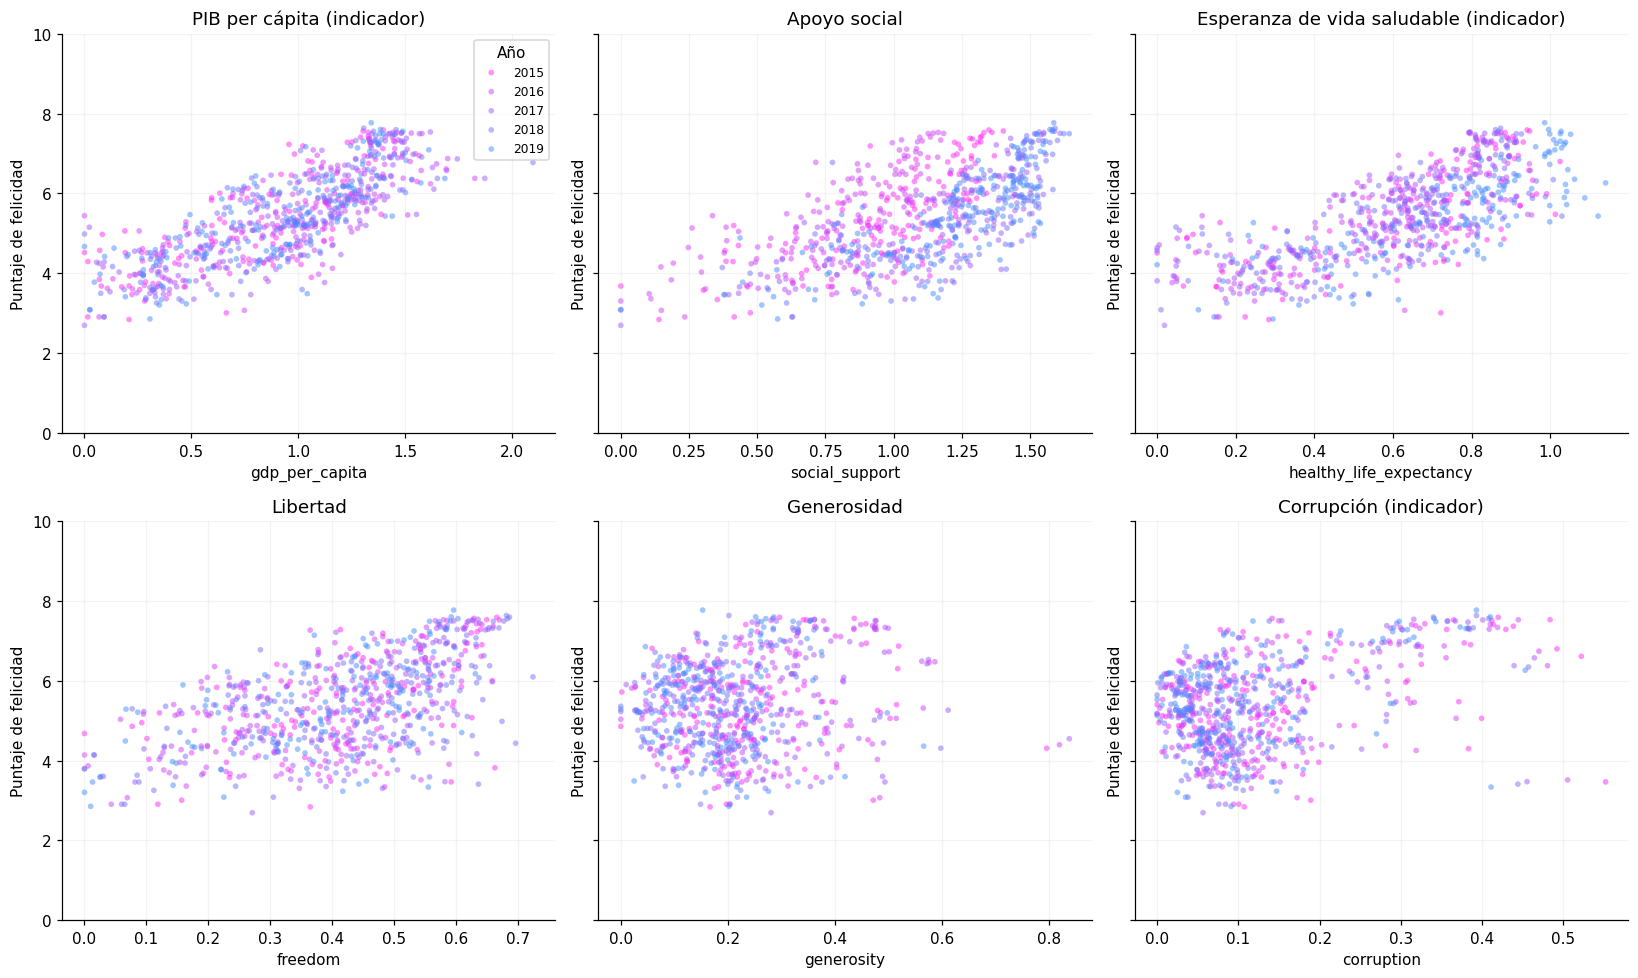

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharey=True)
for ax, feature in zip(axes.flat, FEATURES):
    for year in years:
        subset = df_analisis_numerico[df_analisis_numerico.year.eq(year)]
        ax.scatter(subset[feature], subset[TARGET], s=14, alpha=0.5,
                   color=YEAR_COLORS[year], label=str(year), edgecolors='none')
    ax.set(title=LABELS[feature], xlabel=feature, ylabel='Puntaje de felicidad', ylim=(0, 10))
    ax.grid(alpha=0.15)
axes[0, 0].legend(title='Año', fontsize=8)
finish(fig, '05_features_vs_target.png')

**Interpretación inicial.** PIB per cápita, esperanza de vida saludable y apoyo social muestran asociaciones positivas con el objetivo. Generosidad presenta una relación lineal más débil. Los indicadores pueden representar contribuciones del informe, no valores brutos como dólares o años de vida; conviene verificar su metodología antes de explicar magnitudes o comparar escalas entre años.

## 6. Correlaciones: asociación con el objetivo y entre predictores

Pearson resume asociación lineal y Spearman asociación monótona. El mapa incluye
solo los seis predictores y el objetivo: excluye `happiness_rank`, que deriva del puntaje,
y `year`, que es una referencia temporal. La paleta divergente distingue el signo;
el resto de las figuras utiliza la paleta propuesta.

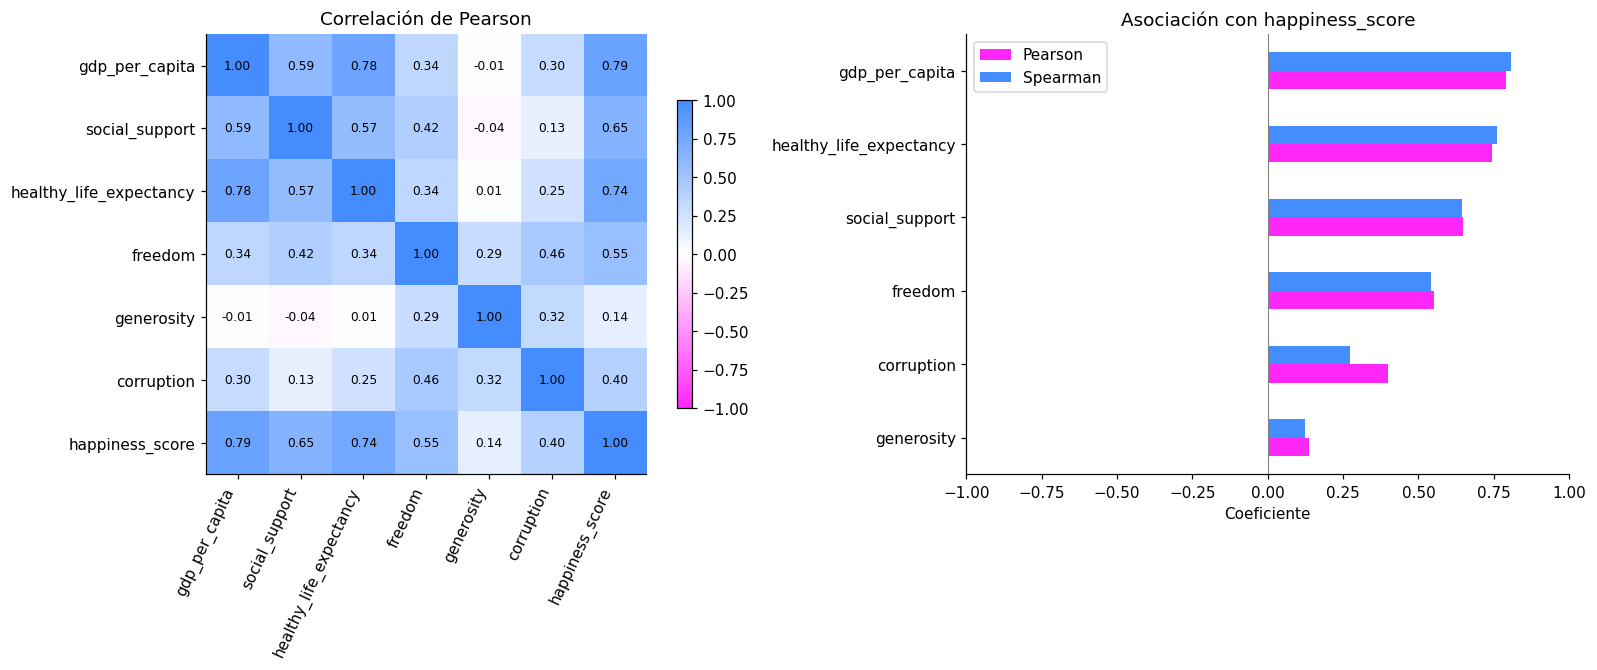

                         Pearson  Spearman
gdp_per_capita             0.789     0.806
social_support             0.649     0.645
healthy_life_expectancy    0.742     0.762
freedom                    0.551     0.542
generosity                 0.138     0.122
corruption                 0.397     0.273


In [6]:
numeric = df_analisis_numerico[FEATURES + [TARGET]]
pearson = numeric.corr(method='pearson')
spearman = numeric.corr(method='spearman')
target_correlations = pd.DataFrame({'Pearson': pearson.loc[FEATURES, TARGET],
                                    'Spearman': spearman.loc[FEATURES, TARGET]})
diverging = LinearSegmentedColormap.from_list('pink_white_blue', [PALETTE[0], '#ffffff', PALETTE[-1]])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
image = axes[0].imshow(pearson, vmin=-1, vmax=1, cmap=diverging)
axes[0].set_xticks(range(len(pearson)), pearson.columns, rotation=65, ha='right')
axes[0].set_yticks(range(len(pearson)), pearson.index)
for i in range(len(pearson)):
    for j in range(len(pearson)): axes[0].text(j, i, f'{pearson.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
axes[0].set_title('Correlación de Pearson')
fig.colorbar(image, ax=axes[0], shrink=0.7)
target_correlations.sort_values('Pearson').plot.barh(ax=axes[1], color=[PALETTE[0], PALETTE[-1]])
axes[1].set(title='Asociación con happiness_score', xlabel='Coeficiente', xlim=(-1, 1))
axes[1].axvline(0, color='gray', linewidth=0.7)
finish(fig, '06_correlations.png')
display(target_correlations.round(3))
pearson.to_csv(TABLE_DIR / 'pearson_correlations.csv')
target_correlations.to_csv(TABLE_DIR / 'target_correlations.csv')

**Interpretación inicial.** En los datos agrupados, Pearson es aproximadamente 0,789 para PIB per cápita, 0,742 para esperanza de vida saludable y 0,649 para apoyo social; para generosidad es 0,138. Una correlación baja no basta para descartar una variable y una alta no garantiza capacidad predictiva fuera de muestra. Las relaciones entre predictores también pueden afectar la interpretación de los coeficientes de una regresión.


### 6.1. Pares de variables más correlacionados

Ordenamos las parejas únicas por el valor absoluto de Pearson; conservamos el signo
y añadimos Spearman. La primera tabla incluye objetivo y predictores del dataset de
modelado. La segunda incluye solo predictores: esta es la relevante para explorar
multicolinealidad. Se excluyen `country` y `year` por su función de identificación y partición.
Una asociación alta con el objetivo no es por sí misma un problema de multicolinealidad.

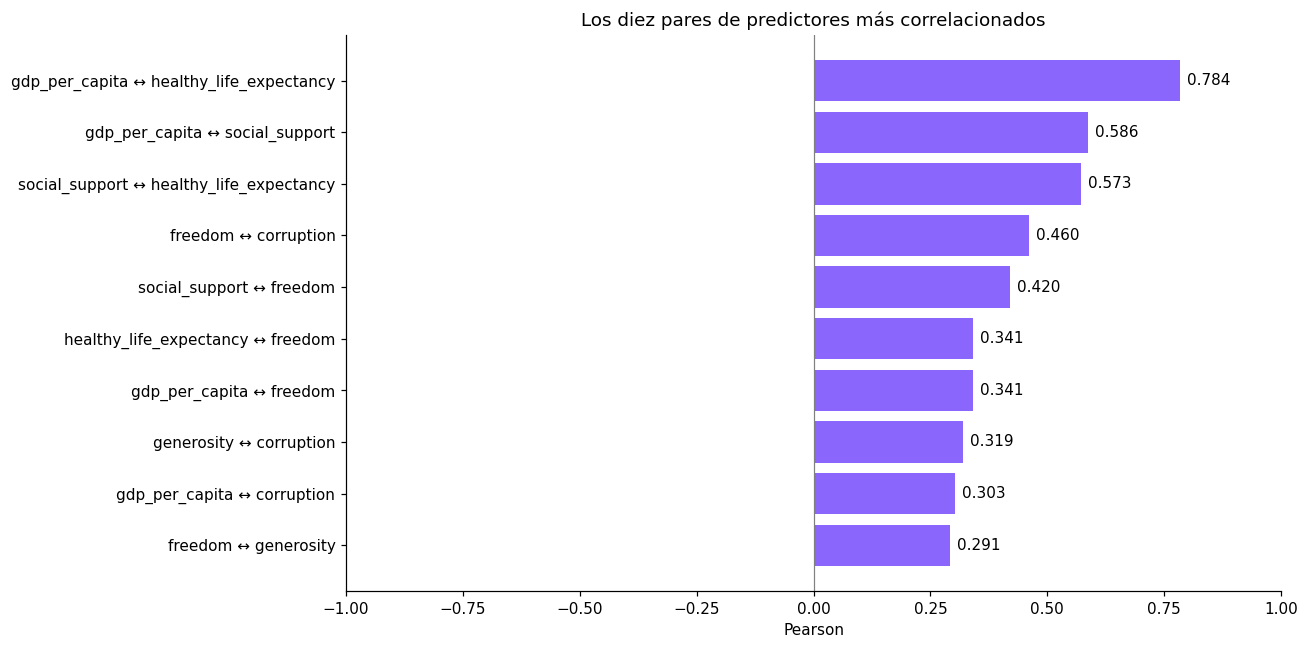

Diez pares más correlacionados: predictores y objetivo
                variable_1               variable_2  ...  spearman  abs_pearson
0           gdp_per_capita          happiness_score  ...     0.806        0.789
1           gdp_per_capita  healthy_life_expectancy  ...     0.795        0.784
2  healthy_life_expectancy          happiness_score  ...     0.762        0.742
3           social_support          happiness_score  ...     0.645        0.649
4           gdp_per_capita           social_support  ...     0.584        0.586
5           social_support  healthy_life_expectancy  ...     0.586        0.573
6                  freedom          happiness_score  ...     0.542        0.551
7                  freedom               corruption  ...     0.426        0.460
8           social_support                  freedom  ...     0.435        0.420
9               corruption          happiness_score  ...     0.273        0.397

[10 rows x 5 columns]
Pares entre predictores, ordenados por |Pe

In [7]:
def ranked_correlations(frame):
    pearson_matrix = frame.corr(method='pearson')
    spearman_matrix = frame.corr(method='spearman')
    records = []
    for i, left in enumerate(frame.columns):
        for right in frame.columns[i + 1:]:
            records.append({'variable_1': left, 'variable_2': right,
                            'pearson': pearson_matrix.loc[left, right],
                            'spearman': spearman_matrix.loc[left, right]})
    return (pd.DataFrame(records).assign(abs_pearson=lambda t: t.pearson.abs())
            .sort_values('abs_pearson', ascending=False).reset_index(drop=True))

model_pairs = ranked_correlations(df_analisis_numerico[FEATURES + [TARGET]])
predictor_pairs = ranked_correlations(df_analisis_numerico[FEATURES])
print('Diez pares más correlacionados: predictores y objetivo')
display(model_pairs.head(10).round(3))
print('Pares entre predictores, ordenados por |Pearson|')
display(predictor_pairs.round(3))
model_pairs.to_csv(TABLE_DIR / 'ranked_model_correlations.csv', index=False)
predictor_pairs.to_csv(TABLE_DIR / 'ranked_predictor_correlations.csv', index=False)

top_pairs = predictor_pairs.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 6))
pair_labels = top_pairs.variable_1 + ' ↔ ' + top_pairs.variable_2
bars = ax.barh(pair_labels, top_pairs.pearson, color=PALETTE[5])
for bar, value in zip(bars, top_pairs.pearson):
    ax.text(value + (0.015 if value >= 0 else -0.015), bar.get_y() + bar.get_height()/2,
            f'{value:.3f}', va='center', ha='left' if value >= 0 else 'right')
ax.axvline(0, color='gray', linewidth=0.8)
ax.set(title='Los diez pares de predictores más correlacionados', xlabel='Pearson', xlim=(-1, 1))
finish(fig, '08_ranked_predictor_correlations.png')

### 6.2. Factor de inflación de la varianza (VIF)

Para cada predictor ajustamos una regresión auxiliar contra los otros cinco,
**con intercepto**, y calculamos `VIF = 1 / (1 − R²)`.
Usamos mínimos cuadrados de NumPy, sin añadir dependencias. Centramos y escalamos
los predictores para mejorar la estabilidad numérica; esto no cambia el VIF con intercepto.
El objetivo, el año y el país no entran en este cálculo.

Como guía exploratoria: **VIF < 5**, sin alerta elevada; **5 ≤ VIF < 10**,
revisar multicolinealidad; **VIF ≥ 10**, alerta alta. Son umbrales orientativos,
no reglas para eliminar variables. El VIF detecta redundancia conjunta que una
correlación por pares puede no mostrar; se relaciona con la estabilidad de los
coeficientes de una regresión, no mide por sí solo la calidad predictiva.

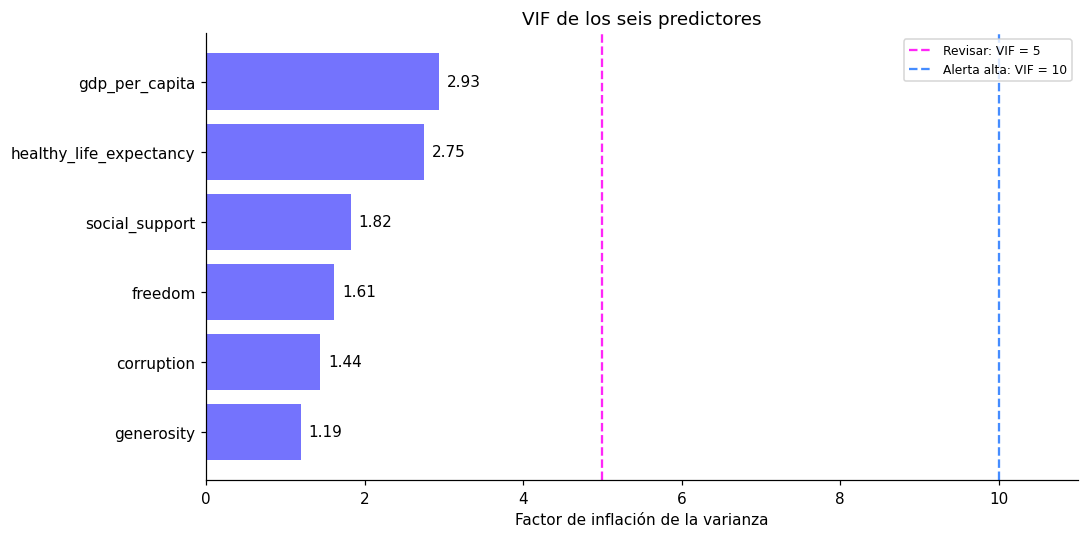

                  variable  auxiliary_r_squared    vif                diagnosis
0           gdp_per_capita                0.659  2.933  Sin alerta elevada (<5)
1  healthy_life_expectancy                0.636  2.751  Sin alerta elevada (<5)
2           social_support                0.451  1.823  Sin alerta elevada (<5)
3                  freedom                0.380  1.612  Sin alerta elevada (<5)
4               corruption                0.305  1.439  Sin alerta elevada (<5)
5               generosity                0.161  1.193  Sin alerta elevada (<5)
Predictores con VIF ≥ 5: Ninguno
Mayor VIF: gdp_per_capita 2.933


In [8]:
def calculate_vif(frame):
    values = frame.to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('El VIF requiere valores finitos, sin nulos.')
    scale = values.std(axis=0)
    if (scale == 0).any():
        raise ValueError('Hay predictores constantes: su VIF no es interpretable.')
    standardized = (values - values.mean(axis=0)) / scale
    records = []
    for index, feature in enumerate(frame.columns):
        response = standardized[:, index]
        other_features = np.delete(standardized, index, axis=1)
        design = np.column_stack([np.ones(len(frame)), other_features])
        coefficients, _, _, _ = np.linalg.lstsq(design, response, rcond=None)
        residuals = response - design @ coefficients
        unexplained_fraction = float(residuals @ residuals / (response @ response))
        vif = np.inf if unexplained_fraction <= np.finfo(float).eps else max(1.0, 1 / unexplained_fraction)
        records.append({'variable': feature, 'auxiliary_r_squared': 1 - unexplained_fraction,
                        'vif': vif, 'diagnosis': 'Alerta alta (≥10)' if vif >= 10 else
                        'Revisar (5–10)' if vif >= 5 else 'Sin alerta elevada (<5)'})
    return pd.DataFrame(records).sort_values('vif', ascending=False).reset_index(drop=True)

vif_table = calculate_vif(df_analisis_numerico[FEATURES])
display(vif_table.round(3))
vif_table.to_csv(TABLE_DIR / 'vif_predictors.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 5))
ordered_vif = vif_table.iloc[::-1]
plot_values = ordered_vif.vif.replace(np.inf, 12)
bars = ax.barh(ordered_vif.variable, plot_values, color=PALETTE[6])
for bar, value in zip(bars, ordered_vif.vif):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            '∞' if np.isinf(value) else f'{value:.2f}', va='center')
ax.axvline(5, color=PALETTE[0], linestyle='--', label='Revisar: VIF = 5')
ax.axvline(10, color=PALETTE[-1], linestyle='--', label='Alerta alta: VIF = 10')
ax.set(title='VIF de los seis predictores', xlabel='Factor de inflación de la varianza',
       xlim=(0, max(11, float(plot_values.max()) * 1.15)))
ax.legend(fontsize=8)
finish(fig, '09_vif_predictors.png')

flagged = vif_table.loc[vif_table.vif.ge(5), 'variable'].tolist()
print('Predictores con VIF ≥ 5:', flagged if flagged else 'Ninguno')
print('Mayor VIF:', vif_table.iloc[0]['variable'], round(vif_table.iloc[0]['vif'], 3))

**Interpretación inicial.** El par de predictores más correlacionado es
`gdp_per_capita` y `healthy_life_expectancy`. Su correlación de Pearson es **0,784**. Los mayores VIF son **2,933** para
`gdp_per_capita` y **2,751** para `healthy_life_expectancy`. Ningún predictor
alcanza VIF = 5; por este criterio no aparece una alerta elevada de multicolinealidad. La tabla y el mensaje
anterior identifican explícitamente las variables que superan el umbral de revisión.
No eliminamos variables automáticamente: cualquier decisión se contrastará con
el objetivo del modelo y su evaluación posterior. Este diagnóstico usa el dataset
agrupado de 2015–2019; conviene repetirlo con el entrenamiento cuando definamos la partición.

## 7. ¿Se mantienen las asociaciones por año?

La correlación global puede ocultar diferencias anuales. Comparamos Pearson dentro
de cada año, sin usar pruebas de significación que supongan independencia de todas las filas.

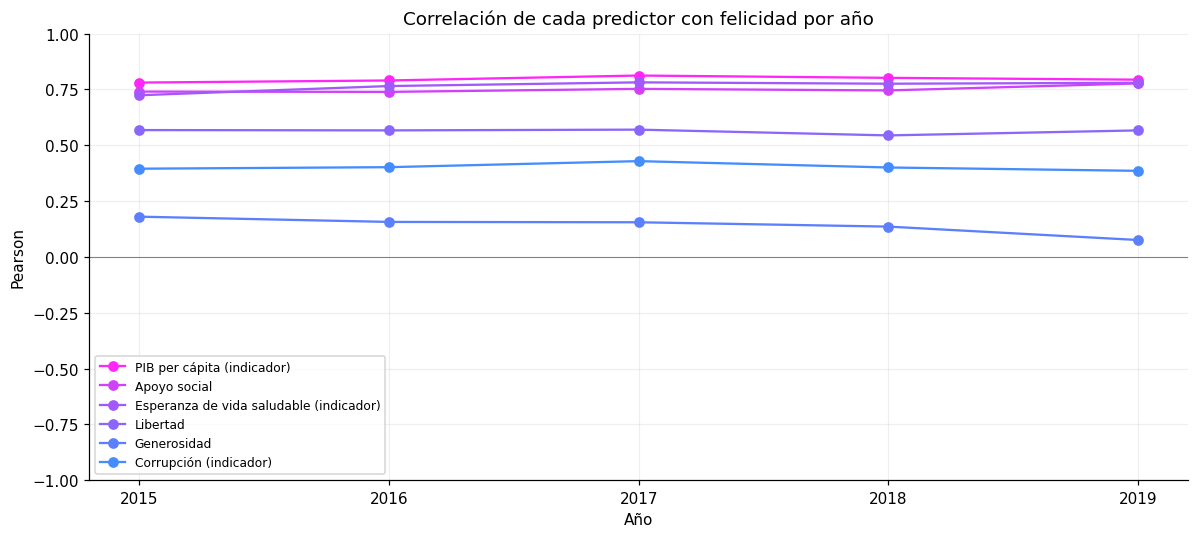

      gdp_per_capita  social_support  ...  generosity  corruption
2015           0.781           0.741  ...       0.180       0.395
2016           0.790           0.739  ...       0.157       0.402
2017           0.812           0.753  ...       0.155       0.429
2018           0.802           0.746  ...       0.136       0.401
2019           0.794           0.777  ...       0.076       0.386

[5 rows x 6 columns]


In [9]:
annual_correlations = pd.DataFrame({year: group[FEATURES + [TARGET]].corr().loc[FEATURES, TARGET]
                                    for year, group in df_analisis_numerico.groupby('year')}).T
fig, ax = plt.subplots(figsize=(11, 5))
for i, feature in enumerate(FEATURES):
    ax.plot(annual_correlations.index, annual_correlations[feature], marker='o',
            label=LABELS[feature], color=PALETTE[[0, 2, 4, 5, 7, 8][i]])
ax.set(title='Correlación de cada predictor con felicidad por año', xlabel='Año',
       ylabel='Pearson', ylim=(-1, 1))
ax.set_xticks(years)
ax.axhline(0, color='gray', linewidth=0.7)
ax.legend(loc='lower left', fontsize=8)
ax.grid(alpha=0.2)
finish(fig, '07_correlations_by_year.png')
display(annual_correlations.round(3))
annual_correlations.to_csv(TABLE_DIR / 'correlations_by_year.csv')

**Interpretación inicial.** Esta comparación permite revisar si la asociación agrupada se sostiene en cada año y detectar cambios que merezcan investigar la metodología. Las diferencias de correlación no demuestran por sí solas un cambio causal. El valor de corrupción imputado en 2018 (0,082) también forma parte de estas estadísticas.